<a href="https://colab.research.google.com/github/juanramirezc5/curso-introduccion-programacion-cientifica/blob/main/PROYECTO-INTEGRADO/notebook/analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO INTEGRADOR  ENTREGABLE 1: PANDAS**
---

## **REALIZADO POR:**
### Juan Manuel Ramirez Ciro - Esteban Villalba Aguirre

### **GRUPO 6**
Desempeño de las pruebas saber 11 en Antioquia (2025)

**Fecha:** 12/11/2026

---
la secretaría de educación debe decidir a qué colegios, jornadas o poblaciones dirigir programas de apoyo

---
### PREGUNTAS

1. ¿Cómo cambia el puntaje global según el estrato, la zona y el tipo de colegio?
2. ¿Tener internet o computador en casa se asocia con mejores resultados?
3. ¿Los estudiantes que trabajan obtienen puntajes más bajos? ¿Depende de cuántas horas trabajan?
4. ¿Que jornadas necesitan más apoyo? ¿Quiénes estudian en ellas?
5. que municipios y grupous concentran los puntajes mas bajos?
6. ¿ el preicfes ayuda?¿quienes participan?

## 1- Carga e inspección

Se carga el CSV  y se revisa su estructura antes de limpiar. Se guarda una copia (df_original) para comparar al final.

In [ ]:
import pandas as pd


ruta_csv = "educacion_saber11_antioquia_2025.csv"

df_original = pd.read_csv(ruta_csv)
df = df_original.copy()
print("Archivo leido desde:", ruta_csv)

Archivo leido desde: educacion_saber11_antioquia_2025.csv


### 1.1 shape

In [ ]:
print(df.shape)

(3250, 23)


Hay 3.250 filas (estudiantes) y 23 columnas, igual que el diccionario.

### 1.2 head

In [ ]:
df.head()

,id_estudiante,municipio,zona,estrato,tipo_colegio,jornada,sexo,edad,educacion_madre,ingreso_familiar_smmlv,...,horas_trabajo_semana,horas_estudio_semana,inasistencias_anio,preparacion_preicfes,puntaje_matematicas,puntaje_lectura_critica,puntaje_ciencias_naturales,puntaje_sociales_ciudadanas,puntaje_ingles,puntaje_global
0,EST-00001,Medellín,Urbana,1,Oficial,Tarde,F,18,Bachillerato,0.9,...,NaN,10.0,4.0,Sí,53.0,44.0,54.0,45.0,51.0,246
1,EST-00002,Medellín,Urbana,2,Oficial,Mañana,M,17,Técnica o tecnológica,NaN,...,18.0,1.0,10.0,Sí,53.0,57.0,42.0,58.0,42.0,258
2,EST-00003,Envigado,Urbana,2,Oficial,Mañana,M,15,NaN,NaN,...,NaN,10.0,5.0,No,48.0,50.0,53.0,49.0,39.0,246
3,EST-00004,Medellín,Urbana,2,Oficial,Única,F,17,Primaria completa,2.6,...,NaN,3.0,8.0,Sí,41.0,36.0,47.0,42.0,51.0,211
4,EST-00005,Medellín,Urbana,2,Oficial,Mañana,F,18,Técnica o tecnológica,NaN,...,NaN,4.0,7.0,Sí,51.0,50.0,45.0,43.0,64.0,243


Cada fila es un estudiante. Ya se ven valores vacíos (NaN), por ejemplo en ingreso_familiar_smmlv y horas_trabajo_semana.

### 1.3 info y dtypes

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3250 entries, 0 to 3249
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_estudiante                3250 non-null   object 
 1   municipio                    3250 non-null   object 
 2   zona                         3250 non-null   object 
 3   estrato                      3250 non-null   int64  
 4   tipo_colegio                 3250 non-null   object 
 5   jornada                      3250 non-null   object 
 6   sexo                         3250 non-null   object 
 7   edad                         3250 non-null   int64  
 8   educacion_madre              2906 non-null   object 
 9   ingreso_familiar_smmlv       1405 non-null   float64
 10  acceso_internet              3158 non-null   object 
 11  computador_hogar             3250 non-null   object 
 12  trabaja                      3250 non-null   object 
 13  horas_trabajo_sema

### 1.4 Tipos incorrectos

Se revisa si hay fechas o números leídos como texto.

In [ ]:
print(df.dtypes.value_counts())
print("Valores de estrato:", sorted(df["estrato"].unique().tolist()))
print("inasistencias_anio tiene solo enteros:", (df["inasistencias_anio"].dropna() % 1 == 0).all())

object     11
float64     9
int64       3
Name: count, dtype: int64
Valores de estrato: [1, 2, 3, 4, 5, 6]
inasistencias_anio tiene solo enteros: True


No hay fechas y los numeros se leyeron bien, así que no hubo tipos que corregir al cargar Las columnas de horas, inasistencias e ingles son decimales solo porque tienen NaN.

### 1.5 describe

In [ ]:
df.describe()

,estrato,edad,ingreso_familiar_smmlv,horas_trabajo_semana,horas_estudio_semana,inasistencias_anio,puntaje_matematicas,puntaje_lectura_critica,puntaje_ciencias_naturales,puntaje_sociales_ciudadanas,puntaje_ingles,puntaje_global
count,3250.000000,3250.000000,1405.000000,755.000000,2980.000000,3023.000000,3250.000000,3250.000000,3250.000000,3250.000000,3128.000000,3250.000000
mean,1.972615,18.128923,1.950036,23.423841,7.186242,6.383725,53.468308,55.102462,51.740308,49.746154,53.145141,262.802769
std,1.049786,4.697792,1.027989,11.661470,6.456445,3.215556,13.055876,12.159918,12.103138,12.612236,16.367288,55.323511
min,1.000000,15.000000,0.400000,4.000000,0.000000,0.000000,13.000000,19.000000,14.000000,9.000000,3.000000,96.000000
25%,1.000000,16.000000,1.200000,15.000000,4.000000,4.000000,44.000000,47.000000,44.000000,41.000000,42.000000,225.000000
50%,2.000000,17.000000,1.700000,21.000000,6.000000,6.000000,53.000000,55.000000,52.000000,49.000000,53.000000,262.000000
75%,3.000000,18.000000,2.400000,33.000000,9.000000,8.000000,62.000000,63.000000,60.000000,58.000000,64.000000,298.000000
max,6.000000,44.000000,11.500000,54.000000,168.000000,22.000000,99.000000,100.000000,100.000000,100.000000,100.000000,493.000000


El puntaje global promedia 263 sobre 500 (de 96 a 493). Llaman la atención la edad máxima de 44 años y las 168 horas de estudio, que se revisan en el diagnóstico.

### 1.6 value_counts

In [ ]:
columnas_categoricas = ["zona", "tipo_colegio", "jornada", "sexo", "educacion_madre",
                        "acceso_internet", "computador_hogar", "trabaja", "preparacion_preicfes", "municipio"]

for columna in columnas_categoricas:
    print(df[columna].value_counts(dropna=False))
    print()

print(df["estrato"].value_counts().sort_index())

zona
Urbana    2748
Rural      502
Name: count, dtype: int64

tipo_colegio
Oficial    2601
Privado     649
Name: count, dtype: int64

jornada
Mañana      1086
Tarde        731
Única        629
Completa     484
Nocturna     214
Sabatina     106
Name: count, dtype: int64

sexo
F    1748
M    1502
Name: count, dtype: int64

educacion_madre
Bachillerato             943
Técnica o tecnológica    765
Primaria completa        583
NaN                      344
Profesional              341
Primaria incompleta      151
Posgrado                 123
Name: count, dtype: int64

acceso_internet
Sí     1580
No     1578
NaN      92
Name: count, dtype: int64

computador_hogar
No    2060
Sí    1190
Name: count, dtype: int64

trabaja
No    2495
Sí     755
Name: count, dtype: int64

preparacion_preicfes
No    2160
Sí    1090
Name: count, dtype: int64

municipio
Medellín    1473
Bello        335
Itagüí       210
Rionegro     199
Apartadó     198
Caucasia     193
Envigado     192
Andes        166
Yarumal      

- Zona: 2.748 urbanos (84,6 %) y 502 rurales.
- Colegio: 2.601 oficiales (80 %) y 649 privados.
- Jornada: la mayor es Mañana (1.086) y la menor es Sabatina (106).
- Estrato: el 74,8 % está en los estratos 1 y 2; los estratos 5 y 6 tienen solo 57 y 39 estudiantes.
- Municipio: 10 municipios, y Medellín tiene el 45 % (1.473).
- Las categorías están escritas siempre igual.

## 2. DIAGNÓSTICO DE CALIDAD

Se revisan faltantes, faltantes "no aplica", atípicos, códigos raros y filas repetidas antes de modificar nada.

### 2.1 Faltantes por columna

In [ ]:
faltantes = df.isna().sum()
porcentaje = (faltantes / len(df) * 100).round(2)

tabla_faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje": porcentaje})
print(tabla_faltantes[tabla_faltantes["faltantes"] > 0].sort_values("porcentaje", ascending=False))

                        faltantes  porcentaje
horas_trabajo_semana         2495       76.77
ingreso_familiar_smmlv       1845       56.77
educacion_madre               344       10.58
horas_estudio_semana          270        8.31
inasistencias_anio            227        6.98
puntaje_ingles                122        3.75
acceso_internet                92        2.83


Hay 5.395 valores vacíos en 7 columnas. Los mayores son horas_trabajo_semana (76,77 %) e ingreso_familiar_smmlv (56,77 %); siguen educacion_madre (10,58 %), horas_estudio_semana (8,31 %), inasistencias_anio (6,98 %), puntaje_ingles (3,75 %) y acceso_internet (2,83 %).

### 2.2 Faltantes

El diccionario dice que horas_trabajo_semana está vacía si el estudiante no trabaja. Se cruza con la columna trabaja.

In [ ]:
print(pd.crosstab(df["trabaja"], df["horas_trabajo_semana"].isna(),
                  rownames=["trabaja"], colnames=["horas_trabajo_semana vacia"]))

horas_trabajo_semana vacia  False  True 
trabaja                                 
No                              0   2495
Sí                            755      0


Los 2.495 que no trabajan están vacíos y los 755 que trabajan tienen dato. Ese faltante es "no aplica" y no se imputa; los faltantes de las otras 6 columnas sí son datos perdidos.

### 2.3 Filas repetidas y códigos raros

In [ ]:
print("Filas repetidas:", df.duplicated().sum())
print("IDs repetidos:", df["id_estudiante"].duplicated().sum())
print("Valores -999 o 999:", df.select_dtypes("number").isin([-999, 999]).sum().sum())

Filas repetidas: 0
IDs repetidos: 0
Valores -999 o 999: 0


No hay filas ni IDs repetidos, ni códigos como -999 o 999, ni categorías escritas de varias formas.

### 2.4 Atípicos y valores imposibles

Se revisan las columnas numéricas con describe y filtros.

In [ ]:
df[["edad", "horas_estudio_semana", "inasistencias_anio", "puntaje_global"]].describe()

,edad,horas_estudio_semana,inasistencias_anio,puntaje_global
count,3250.000000,2980.000000,3023.000000,3250.000000
mean,18.128923,7.186242,6.383725,262.802769
std,4.697792,6.456445,3.215556,55.323511
min,15.000000,0.000000,0.000000,96.000000
25%,16.000000,4.000000,4.000000,225.000000
50%,17.000000,6.000000,6.000000,262.000000
75%,18.000000,9.000000,8.000000,298.000000
max,44.000000,168.000000,22.000000,493.000000


In [ ]:
print(df["horas_estudio_semana"].dropna().sort_values().tail(8).tolist())
print()
print(df.loc[df["horas_estudio_semana"] > 60, ["id_estudiante", "jornada", "horas_estudio_semana", "puntaje_global"]])

[26.0, 27.0, 29.0, 29.0, 90.0, 90.0, 168.0, 168.0]

     id_estudiante jornada  horas_estudio_semana  puntaje_global
327      EST-00328  Mañana                 168.0             239
986      EST-00987  Mañana                 168.0             267
2984     EST-02985   Tarde                  90.0             214
3016     EST-03017   Tarde                  90.0             359


Hay 4 valores imposibles en horas_estudio_semana: dos de 168 horas (la semana completa) y dos de 90. Los siguientes más altos son 29, 29, 27 y 26, por eso solo se consideran imposibles los que pasan de 60.

In [ ]:
print(df.groupby("jornada")["edad"].agg(["count", "min", "median", "max"]))
print()

mayores_20 = df.loc[df["edad"] > 20]
print("Estudiantes de mas de 20 anios:", len(mayores_20))
print(mayores_20["jornada"].value_counts())

          count  min  median  max
jornada                          
Completa    484   15    17.0   20
Mañana     1086   15    17.0   20
Nocturna    214   18    29.0   44
Sabatina    106   18    30.0   44
Tarde       731   15    17.0   20
Única       629   15    17.0   20

Estudiantes de mas de 20 anios: 273
jornada
Nocturna    179
Sabatina     94
Name: count, dtype: int64


Los 273 estudiantes de más de 20 años estan todos en Nocturna y Sabatina (jornadas de adultos, edad mediana de 29 y 30). La edaad de hasta 44 años es atipica pero valida.

In [ ]:
columnas_puntaje = ["puntaje_matematicas", "puntaje_lectura_critica", "puntaje_ciencias_naturales",
                   "puntaje_sociales_ciudadanas", "puntaje_ingles"]

for columna in columnas_puntaje:
    print(columna, "fuera de 0-100:", ((df[columna] < 0) | (df[columna] > 100)).sum())

print("puntaje_global fuera de 0-500:", ((df["puntaje_global"] < 0) | (df["puntaje_global"] > 500)).sum())
print("estrato fuera de 1-6:", ((df["estrato"] < 1) | (df["estrato"] > 6)).sum())
print("inasistencias negativas:", (df["inasistencias_anio"] < 0).sum())

puntaje_matematicas fuera de 0-100: 0
puntaje_lectura_critica fuera de 0-100: 0
puntaje_ciencias_naturales fuera de 0-100: 0
puntaje_sociales_ciudadanas fuera de 0-100: 0
puntaje_ingles fuera de 0-100: 0
puntaje_global fuera de 0-500: 0
estrato fuera de 1-6: 0
inasistencias negativas: 0


Los puntajes, el estrato y las inasistencias están dentro de su rango.

In [ ]:
# Puntaje global = promedio ponderado (3, 3, 3, 3, 1) llevado a escala de 500
con_ingles = df.dropna(subset=["puntaje_ingles"])
global_calculado = (3 * (con_ingles["puntaje_matematicas"] + con_ingles["puntaje_lectura_critica"]
                         + con_ingles["puntaje_ciencias_naturales"] + con_ingles["puntaje_sociales_ciudadanas"])
                    + con_ingles["puntaje_ingles"]) / 13 * 5
diferencia = (global_calculado - con_ingles["puntaje_global"]).abs()
print("Diferencia maxima:", round(diferencia.max(), 2))

sin_ingles = df.loc[df["puntaje_ingles"].isna()]
print("Estudiantes sin ingles:", len(sin_ingles), "| con puntaje global:", sin_ingles["puntaje_global"].notna().sum())

Diferencia maxima: 0.46
Estudiantes sin ingles: 122 | con puntaje global: 122


El puntaje global coincide con la formulaa del diccionario (diferencia máxima de 0,46 por redondeo). Los 122 estudiantes sin ingles sí tienen puntaje globak.

### 2.5 Faltantes de ingreso por estrato

In [ ]:
print((df["ingreso_familiar_smmlv"].isna().groupby(df["estrato"]).mean() * 100).round(1))

estrato
1    57.5
2    56.5
3    59.1
4    47.3
5    47.4
6    56.4
Name: ingreso_familiar_smmlv, dtype: float64


Los faltantes de ingreso están en todos los estratos (entre 47 % y 59 %), no en un grupo en particular.

## 3. LIMPIEZA

Se toman las decisiones del diagnóstico y se muestra el costo de cada una (filas y columnas antes y después, valores imputados). Se trabaja sobre df y df_original queda sin tocar.

In [ ]:
print("Tamano inicial:", df.shape)
print("Faltantes totales:", df.isna().sum().sum())

Tamano inicial: (3250, 23)
Faltantes totales: 5395


### 3.1 Eliminar ingreso_familiar_smmlv

Tiene 56,77 % de faltantes y están repartidos en todos los estratosasí que imputarla sera inventar más de la mitad de la columna El nivel socioeconomico ya se mide con estracto

In [ ]:
print("Antes:", df.shape)
df = df.drop(columns=["ingreso_familiar_smmlv"])
print("Despues:", df.shape)

Antes: (3250, 23)
Despues: (3250, 22)


Costo: 1 columna menos (23 a 22) y ninguna fila perdiendose 1845 valores

### 3.2 Valores imposibles de horas_estudio_semana

Las 4 filas con 90 y 168 horas se convierten en faltantes, no se eliminan porque el resto de sus datos sí es valido.

In [ ]:
nulos_antes = df["horas_estudio_semana"].isna().sum()
df.loc[df["horas_estudio_semana"] > 60, "horas_estudio_semana"] = float("nan")
nulos_despues = df["horas_estudio_semana"].isna().sum()

print("Filas:", len(df))
print("Faltantes antes:", nulos_antes, "| despues:", nulos_despues)
print("Valores convertidos en faltantes:", nulos_despues - nulos_antes)

Filas: 3250
Faltantes antes: 270 | despues: 274
Valores convertidos en faltantes: 4


Costo: 4 valores convertidos en faltantes y 0 filas eliminadas.

### 3.3 Imputar horas_estudio_semana con la mediana

Es numérica y sesgada a la derecha (promedio 7,02 contra mediana 6), así que la mediana representa mejor al estudiante típico.

In [ ]:
print("Promedio:", round(df["horas_estudio_semana"].mean(), 2))
print("Mediana:", df["horas_estudio_semana"].median())

mediana_horas = df["horas_estudio_semana"].median()
imputados_horas = df["horas_estudio_semana"].isna().sum()
df["horas_estudio_semana"] = df["horas_estudio_semana"].fillna(mediana_horas)
print("Valores imputados:", imputados_horas)

Promedio: 7.02
Mediana: 6.0
Valores imputados: 274


Costo: 274 valores imputados con 6 horas (8,4 % de la columna).

### 3.4 Imputar inasistencias_anio con la mediana por jornada

Es numerico y su valor cambia según la jornada: 8 días en Nocturna y Sabatina y 6 en las demás. Una mediana general (6)

In [ ]:
print(df.groupby("jornada")["inasistencias_anio"].agg(["count", "median"]))

imputados_inasistencias = df["inasistencias_anio"].isna().sum()
mediana_jornada = df.groupby("jornada")["inasistencias_anio"].transform("median")
df["inasistencias_anio"] = df["inasistencias_anio"].fillna(mediana_jornada)
print("Valores imputados:", imputados_inasistencias)

          count  median
jornada                
Completa    449     6.0
Mañana     1011     6.0
Nocturna    198     8.0
Sabatina     96     8.0
Tarde       690     6.0
Única       579     6.0
Valores imputados: 227


Costo: 227 valores imputados (6,98 % de la columna).

### 3.5 Imputar educacion_madre con la moda por estrato

Es categorica, por eso se usa la moda, y la moda cambia con el estrato: Bachillerato en 1 y 2, Técnica o tecnologica en 3 Profesional en 4 y Posgrado en 5 y 6

In [ ]:
print(df.groupby("estrato")["educacion_madre"].agg(lambda serie: serie.mode()[0]))

imputados_madre = df["educacion_madre"].isna().sum()
moda_estrato = df.groupby("estrato")["educacion_madre"].transform(lambda serie: serie.mode()[0])
df["educacion_madre"] = df["educacion_madre"].fillna(moda_estrato)
print("Valores imputados:", imputados_madre)

estrato
1             Bachillerato
2             Bachillerato
3    Técnica o tecnológica
4              Profesional
5                 Posgrado
6                 Posgrado
Name: educacion_madre, dtype: object
Valores imputados: 344


Costo: 344 valores imputados (10,58 % de la columna), la imputación más grande.

### 3.6 Imputar acceso_internet con la moda por zona

En total casi hay empate (1.580 Sí y 1.578 No), pero por zona no: en la rural predomina No (76,8 %) y en la urbana Sí (54,9 %).

In [ ]:
print(pd.crosstab(df["zona"], df["acceso_internet"], normalize="index").round(3))

imputados_internet = df["acceso_internet"].isna().sum()
moda_zona = df.groupby("zona")["acceso_internet"].transform(lambda serie: serie.mode()[0])
df["acceso_internet"] = df["acceso_internet"].fillna(moda_zona)
print("Valores imputados:", imputados_internet)

acceso_internet     No     Sí
zona                         
Rural            0.768  0.232
Urbana           0.451  0.549
Valores imputados: 92


Costo: 92 valores imputados (2,83 % de la columna). Los resultados de internet de la pregunta 2 incluyen esos valores.

### 3.7 Tipo de inasistencias_anio

Sin faltantes y con días completos, se pasa de decimal a entero.

In [ ]:
df["inasistencias_anio"] = df["inasistencias_anio"].astype(int)
print(df["inasistencias_anio"].dtype)

int64


### 3.8 Lo que no se imputa

- horas_trabajo_semana: es "no aplica" (no trabaja).
- puntaje_ingles (122 faltantes): es un resultado de la prueba y el puntaje global está completo.
- edad: los valores altos son válidos y se conservan.

### 3.9 Resumen del costo

In [ ]:
print("Tamano final:", df.shape)
print("Filas conservadas:", len(df), "de", len(df_original))
print("Total de valores imputados:", imputados_horas + imputados_inasistencias + imputados_madre + imputados_internet)
print()

faltantes_finales = df.isna().sum()
print(faltantes_finales[faltantes_finales > 0])

Tamano final: (3250, 22)
Filas conservadas: 3250 de 3250
Total de valores imputados: 937

horas_trabajo_semana    2495
puntaje_ingles           122
dtype: int64


Quedan 3.250 filas (100 % de las originales) y 22 columnas. Se imputaron 937 valores (274 + 227 + 344 + 92) y los únicos faltantes que quedan son los dos que no se imputaron.

##  PREGUNTAS

### PREGUNTA 1: ¿cómo cambia el puntaje global según el estrato, la zona y el tipo de colegio?

Se agrupa por cada variable y se calcula el count y el promedio del puntaje global.

In [ ]:
por_estrato = df.groupby("estrato")["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_estrato)

         count   mean
estrato              
1         1285  232.0
2         1146  264.5
3          577  295.3
4          146  322.4
5           57  351.5
6           39  393.1


In [ ]:
por_zona = df.groupby("zona")["puntaje_global"].agg(["count", "mean"]).round(1)
por_colegio = df.groupby("tipo_colegio")["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_zona)
print()
print(por_colegio)

        count   mean
zona                
Rural     502  227.7
Urbana   2748  269.2

              count   mean
tipo_colegio              
Oficial        2601  251.9
Privado         649  306.3


In [ ]:
cruce = df.groupby(["tipo_colegio", "zona"])["puntaje_global"].agg(["count", "mean"]).round(1)
print(cruce.sort_values("mean", ascending=False))

                     count   mean
tipo_colegio zona                
Privado      Urbana    562  313.0
             Rural      87  263.6
Oficial      Urbana   2186  258.0
             Rural     415  220.2


In [ ]:
brecha_estrato = por_estrato.loc[6, "mean"] - por_estrato.loc[1, "mean"]
brecha_zona = por_zona.loc["Urbana", "mean"] - por_zona.loc["Rural", "mean"]
brecha_colegio = por_colegio.loc["Privado", "mean"] - por_colegio.loc["Oficial", "mean"]

print("Estrato 6 - estrato 1:", round(brecha_estrato, 1))
print("Urbana - rural:", round(brecha_zona, 1))
print("Privado - oficial:", round(brecha_colegio, 1))

Estrato 6 - estrato 1: 161.1
Urbana - rural: 41.5
Privado - oficial: 54.4


El puntaje sube con el estrato: 232,0 en el estrato 1 (1.285 estudiantes) y 393,1 en el 6 (39), una diferencia de 161,1. Urbana 269,2 contra rural 227,7 (41,5 puntos) y privado 306,3 contra oficial 251,9 (54,4 puntos). El grupo más bajo y numeroso es **oficial rural: 220,2 con 415 estudiantes**, buen candidato para los programas de apoyo. Los estratos 5 y 6 tienen pocos datos.

### PREGUNTA 2: Tener internet o pc mejora los resultados?

Se compara el promedio con y sin internet, con y sin computador y por zona.

In [ ]:
por_internet = df.groupby("acceso_internet")["puntaje_global"].agg(["count", "mean"]).round(1)
por_computador = df.groupby("computador_hogar")["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_internet)
print()
print(por_computador)

                 count   mean
acceso_internet              
No                1593  244.4
Sí                1657  280.5

                  count   mean
computador_hogar              
No                 2060  251.2
Sí                 1190  282.9


In [ ]:
internet_zona = df.groupby(["zona", "acceso_internet"])["puntaje_global"].agg(["count", "mean"]).round(1)
print(internet_zona)
print()
print("Porcentaje con internet por zona:")
print((pd.crosstab(df["zona"], df["acceso_internet"], normalize="index")["Sí"] * 100).round(1))

                        count   mean
zona   acceso_internet              
Rural  No                 389  222.1
       Sí                 113  247.3
Urbana No                1204  251.6
       Sí                1544  282.9

Porcentaje con internet por zona:
zona
Rural     22.5
Urbana    56.2
Name: Sí, dtype: float64


In [ ]:
ambos = df.groupby(["acceso_internet", "computador_hogar"])["puntaje_global"].agg(["count", "mean"]).round(1)
print(ambos.sort_values("mean", ascending=False))

                                  count   mean
acceso_internet computador_hogar              
Sí              Sí                  672  298.5
                No                  985  268.3
No              Sí                  518  262.8
                No                 1075  235.5


In [ ]:
brecha_internet = por_internet.loc["Sí", "mean"] - por_internet.loc["No", "mean"]
brecha_computador = por_computador.loc["Sí", "mean"] - por_computador.loc["No", "mean"]
brecha_ambos = ambos.loc[("Sí", "Sí"), "mean"] - ambos.loc[("No", "No"), "mean"]

print("Con internet - sin internet:", round(brecha_internet, 1))
print("Con computador - sin computador:", round(brecha_computador, 1))
print("Con ambos - con ninguno:", round(brecha_ambos, 1))

Con internet - sin internet: 36.1
Con computador - sin computador: 31.7
Con ambos - con ninguno: 63.0


Con internet el promedio es 280,5 (1.657) y sin internet 244,4 (1.593): 36,1 puntos. Con computador 282,9 y sin computador 251,2: 31,7 puntos. La diferencia por internet se mantiene dentro de cada zona (25,2 en la rural y 31,3 en la urbana), y solo el 22,5 % de los rurales tiene internet contra el 56,2 % de los urbanos. Con internet y computador el promedio es 298,5 y con ninguno 235,5 (63,0 puntos); ese último grupo tiene 1.075 estudiantes (33 %) y es el público de un programa de conectividad.

### PREGUNTA 3: ¿los que trabajan obtienen puntajes más bajos? ¿depende de las horas?

Se compara por trabaja, por rangos de horas de trabajo (pd.cut) y por jornada.

In [ ]:
por_trabajo = df.groupby("trabaja")["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_trabajo)

         count   mean
trabaja              
No        2495  272.0
Sí         755  232.3


In [ ]:
trabajadores = df.loc[df["trabaja"] == "Sí"].copy()
trabajadores["rango_horas"] = pd.cut(trabajadores["horas_trabajo_semana"], bins=[0, 15, 30, 60],
                                     labels=["1 a 15 h", "16 a 30 h", "31 a 60 h"])
por_horas = trabajadores.groupby("rango_horas", observed=True)["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_horas)

             count   mean
rango_horas              
1 a 15 h       215  240.5
16 a 30 h      325  234.5
31 a 60 h      215  220.7


In [ ]:
trabaja_jornada = df.groupby(["jornada", "trabaja"])["puntaje_global"].agg(["count", "mean"]).round(1)
print(trabaja_jornada)

                  count   mean
jornada  trabaja              
Completa No         409  311.2
         Sí          75  277.4
Mañana   No         875  267.8
         Sí         211  234.5
Nocturna No          53  259.8
         Sí         161  221.1
Sabatina No          32  252.0
         Sí          74  213.5
Tarde    No         609  262.2
         Sí         122  227.5
Única    No         517  262.3
         Sí         112  231.6


In [ ]:
brecha_trabajo = por_trabajo.loc["No", "mean"] - por_trabajo.loc["Sí", "mean"]
brecha_horas = por_horas.loc["1 a 15 h", "mean"] - por_horas.loc["31 a 60 h", "mean"]

print("No trabaja - trabaja:", round(brecha_trabajo, 1))
print("1 a 15 h - 31 a 60 h:", round(brecha_horas, 1))
print()

medias = df.groupby(["jornada", "trabaja"])["puntaje_global"].mean().unstack()
print("Diferencia (no trabaja - trabaja) por jornada:")
print((medias["No"] - medias["Sí"]).round(1))

No trabaja - trabaja: 39.7
1 a 15 h - 31 a 60 h: 19.8

Diferencia (no trabaja - trabaja) por jornada:
jornada
Completa    33.8
Mañana      33.3
Nocturna    38.7
Sabatina    38.5
Tarde       34.7
Única       30.7
dtype: float64


Quienes trabajan promedian 232,3 (755) y quienes no 272,0 (2.495): 39,7 puntos menos. Entre quienes trabajan el puntaje baja con las horas: 240,5 con 1 a 15 horas, 234,5 co 16 a 30 y 220,7 con más de 30 (19,8 puntos de diferencia). En todas las jornadas los que trabajan sacan entre 31 y 39 puntos menos; en Sabatina el grupo que no trabaja es pequeño (32 estudiantes)

### PREGUNTA 4: ¿qué jornadas necesitan más apoyo y quiénes estudian en ellas?

Se ordenan las jornadas por promedio y se describe su perfil (edad, trabajo, zona, internet y tipo de colegio).

In [ ]:
por_jornada = df.groupby("jornada")["puntaje_global"].agg(["count", "mean"]).round(1)
por_jornada["edad_mediana"] = df.groupby("jornada")["edad"].median()
print(por_jornada.sort_values("mean"))

          count   mean  edad_mediana
jornada                             
Sabatina    106  225.1          30.0
Nocturna    214  230.7          29.0
Tarde       731  256.4          17.0
Única       629  256.8          17.0
Mañana     1086  261.4          17.0
Completa    484  305.9          17.0


In [ ]:
perfil = pd.DataFrame()
perfil["pct_trabaja"] = pd.crosstab(df["jornada"], df["trabaja"], normalize="index")["Sí"] * 100
perfil["pct_rural"] = pd.crosstab(df["jornada"], df["zona"], normalize="index")["Rural"] * 100
perfil["pct_internet"] = pd.crosstab(df["jornada"], df["acceso_internet"], normalize="index")["Sí"] * 100
perfil["pct_oficial"] = pd.crosstab(df["jornada"], df["tipo_colegio"], normalize="index")["Oficial"] * 100
print(perfil.round(1))

          pct_trabaja  pct_rural  pct_internet  pct_oficial
jornada                                                    
Completa         15.5       13.6          63.6          0.0
Mañana           19.4       16.0          50.3         84.8
Nocturna         75.2       12.6          50.5        100.0
Sabatina         69.8       18.9          47.2        100.0
Tarde            16.7       16.6          48.7        100.0
Única            17.8       14.9          45.9        100.0


In [ ]:
estudiantes_bajas = por_jornada.loc[["Nocturna", "Sabatina"], "count"].sum()
print("Estudiantes en Nocturna y Sabatina:", estudiantes_bajas)
print("Porcentaje del total:", round(estudiantes_bajas / len(df) * 100, 1))
print("Completa - Sabatina:", round(por_jornada.loc["Completa", "mean"] - por_jornada.loc["Sabatina", "mean"], 1))

Estudiantes en Nocturna y Sabatina: 320
Porcentaje del total: 9.8
Completa - Sabatina: 80.8


Las jornadas más bajas son Sabatina (225,1; 106 estudiantes) y Nocturna (230,7; 214), que juntas suman 320 estudiantes (9,8 %). Allí estudian adultos (edad mediana de 29 y 30 años) y trabaja el 75,2 % y el 69,8 %, frente a 15,5 % a 19,4 % en las demás.

### PREGUNTA 5: ¿qué municipios y grupos concentran los puntajes más bajos?

Se ordenan los municipios por promedio y se cuentan los estudiantes con menos de 200 puntos.

In [ ]:
por_municipio = df.groupby("municipio")["puntaje_global"].agg(["count", "mean"]).round(1)
por_municipio["pct_rural"] = (pd.crosstab(df["municipio"], df["zona"], normalize="index")["Rural"] * 100).round(1)
print(por_municipio.sort_values("mean"))
print()
print("Diferencia entre el municipio mas alto y el mas bajo:", round(por_municipio["mean"].max() - por_municipio["mean"].min(), 1))

           count   mean  pct_rural
municipio                         
Yarumal      149  237.7       44.3
Turbo        135  241.9       43.0
Andes        166  242.7       50.6
Apartadó     198  242.9       35.9
Caucasia     193  244.9       33.2
Rionegro     199  251.4       26.6
Itagüí       210  269.4        6.2
Bello        335  270.3        5.7
Medellín    1473  271.9        4.0
Envigado     192  274.7        7.8

Diferencia entre el municipio mas alto y el mas bajo: 37.0


In [ ]:
puntaje_bajo = df.loc[df["puntaje_global"] < 200]
print("Estudiantes con menos de 200 puntos:", len(puntaje_bajo), "de", len(df))
print("Porcentaje:", round(len(puntaje_bajo) / len(df) * 100, 1))
print()
print((puntaje_bajo["zona"].value_counts() / df["zona"].value_counts() * 100).round(1))
print()
print((puntaje_bajo["jornada"].value_counts() / df["jornada"].value_counts() * 100).round(1).sort_values(ascending=False))

Estudiantes con menos de 200 puntos: 405 de 3250
Porcentaje: 12.5

zona
Urbana     9.6
Rural     28.1
Name: count, dtype: float64

jornada
Sabatina    31.1
Nocturna    24.8
Tarde       12.9
Mañana      12.6
Única       11.1
Completa     3.7
Name: count, dtype: float64


Los municipios más bajos son Yarumal (237,7; 149 estudiantes), Turbo (241,9), Andes (242,7), Apartadó (242,9) y Caucasia (244,9), y tienen entre 33 % y 51 % de estudiantes rurales (en Medellín, Bello, Itagüí y Envigado es entre 4 % y 8 %). El 12,5 % de los estudiantes (405) tiene menos de 200 puntos: el 28,1 % de los rurales contra el 9,6 % de los urbanos, y el 31,1 % de Sabatina contra el 3,7 % de Completa.

### PREGUNTA 6 (propuesta del grupo): ¿el preicfes se asocia con mejores puntajes y quién accede a él?

Se pregunta por el preicfes porque uno de los programas de la decisión es el preicfes gratuito.

In [ ]:
por_preicfes = df.groupby("preparacion_preicfes")["puntaje_global"].agg(["count", "mean"]).round(1)
print(por_preicfes)
print("Con preicfes - sin preicfes:", round(por_preicfes.loc["Sí", "mean"] - por_preicfes.loc["No", "mean"], 1))
print()
print("Porcentaje que tomo preicfes por estrato:")
print((pd.crosstab(df["estrato"], df["preparacion_preicfes"], normalize="index")["Sí"] * 100).round(1))

                      count   mean
preparacion_preicfes              
No                     2160  250.8
Sí                     1090  286.6
Con preicfes - sin preicfes: 35.8

Porcentaje que tomo preicfes por estrato:
estrato
1    19.8
2    35.2
3    47.8
4    52.7
5    75.4
6    92.3
Name: Sí, dtype: float64


Con preicfes el promedio es 286,6 (1.090) y sin preicfes 250,8 (2.160): 35,8 puntos. Pero lo tomó el 19,8 % del estrato 1 y el 92,3 % del estrato 6, así que parte de la diferencia puede deberse al estrato. Un preicfes gratuito llegaría a estratos 1 y 2 (74,8 % de los estudiantes), pero no se puede asegurar cuánto subiría el puntaje.

## 5. CONCLUSIONES PARCIALES

Resumen de lo que responden los datos hasta aquí.

**Limpieza:** no hubo filas repetidas ni centinelas. Se eliminó 1 columna

**Hallazgos:**
1. El puntaje sube con el estrato, es mayor en lo urbano y en colegios privados. El grupo más bajo y numeroso es oficial rural (220,2; 415 estudiantes).
2. Tener internet y computador se asocia con 63,0 puntos más que no tener ninguno, y solo el 22,5 % de los rurales tiene internet.
3. Trabajar se asocia con 39,7 puntos menos, y más horas de trabajo con menos puntaje.
4. Sabatina y Nocturna tienen los puntajes más bajos y sus estudiantes son adultos que trabajan.
5. Los municipios más bajos son los de mayor población rural (Yarumal, Turbo, Andes, Apartadó y Caucasia).
6. El preicfes se asocia con 35,8 puntos más, pero lo toman sobre todo los estratos altos.

**Para la decisión:** priorizar colegios oficiales rurales, jornadas Nocturna y Sabatina, y estudiantes sin internet ni computador.

**Limitaciones:** los datos son sintéticos y las diferencias son asociaciones, no causas; el estrato, la zona y el tipo de colegio están relacionados entre sí.



___

#**ENTREGABLE 2:MATPLOTLIB Y SEABORN**

___

### 6. GRAFICAS

Se importa las librerias

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


os.makedirs("visualizaciones", exist_ok=True)
print("Filas y columnas del df limpio:", df.shape)
print("Carpeta lista: visualizaciones/")

Filas y columnas del df limpio: (3250, 22)
Carpeta lista: visualizaciones/


## 7. GRÁFICAS UNIVARIADAS

Cada una mira una sola columna.

### GRÁFICA 1
Se cuentan cuántos estudiantes caen en cada tramo de puntaje

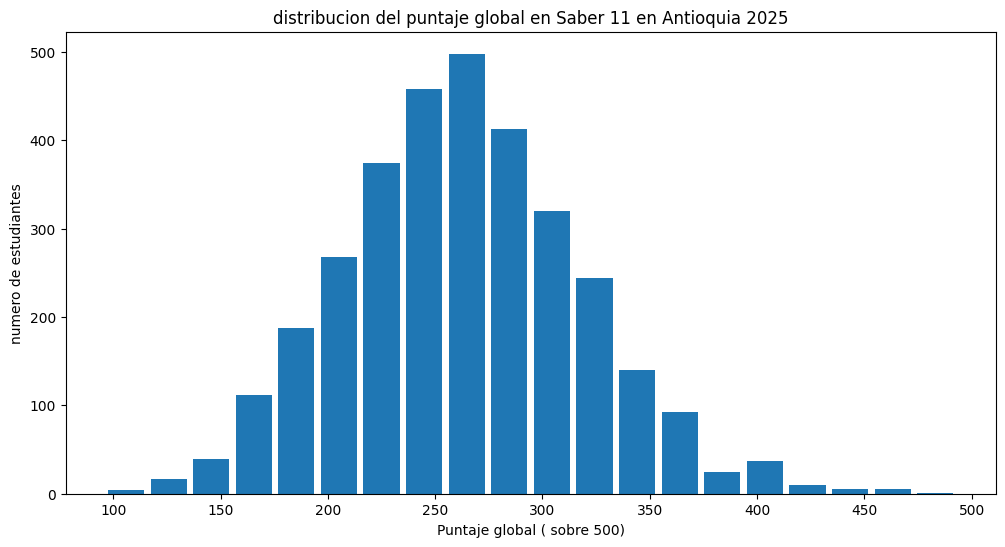

262.8 262.0


In [ ]:
fig, ax = plt.subplots(figsize=( 12, 6))
ax.hist(df["puntaje_global"], bins= 20,  rwidth=0.85 )
ax.set_title("distribucion del puntaje global en Saber 11 en Antioquia 2025")
ax.set_xlabel("Puntaje global ( sobre 500)")
ax.set_ylabel("numero de estudiantes")
plt.savefig("visualizaciones/histograma-puntaje-global.png", dpi=150, bbox_inches="tight")
plt.show()

print(round(df["puntaje_global"].mean(), 2), df["puntaje_global"].median())

**pregunta:** distribucin de los puntajes

**Observación:** hay un solo pico aproximadamente entre 255 y 275 puntos (498 estudiantes) lo que implica que se necesita un apoyo a los que sacan menos de 150


### GRÁFICA 2
sns.countplot cuenta las filas de cada jornada y dibuja una barra por categoría.

jornada
Mañana      1086
Tarde        731
Única        629
Completa     484
Nocturna     214
Sabatina     106
Name: count, dtype: int64


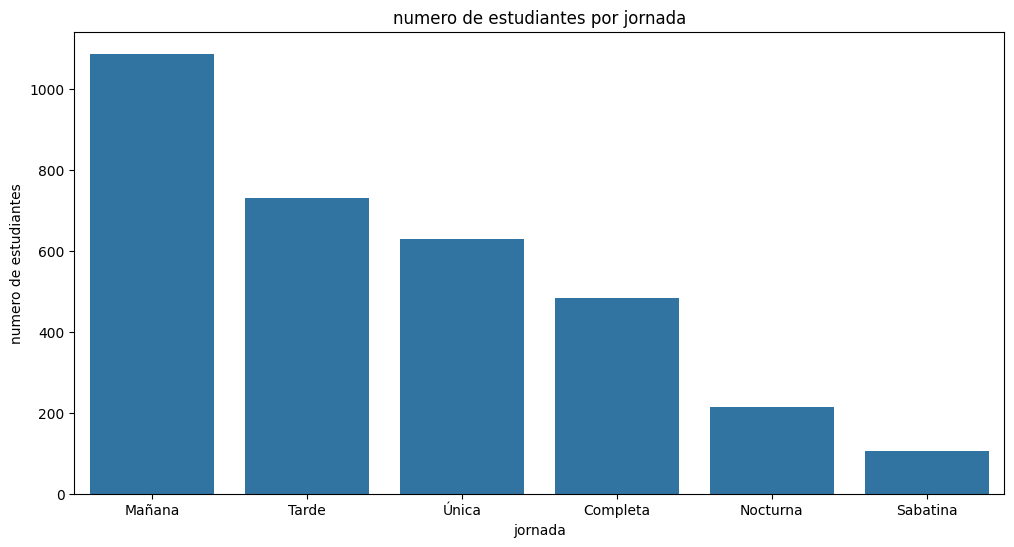

In [ ]:
orden_jornada = df["jornada"].value_counts().index
print(df["jornada"].value_counts())

plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, x="jornada", order=orden_jornada)
ax.set_title("numero de estudiantes por jornada")
ax.set_xlabel("jornada")
ax.set_ylabel("numero de estudiantes")
plt.savefig("visualizaciones/barras-estudiantes-por-jornada.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿cuántos estudiantes hay en cada jornada? (pregunta 4)

**Observación:** Mañana es la más grande con 1.086 estudiantes, luego Tarde 731, Única 629 y Completa 484. Nocturna 214 y Sabatina 106
lo que implica que las jornadas con peores puntajes la nocturna y sabatina tienen pocos estudiantes lo que lo hace inestable en el puntaje

### GRÁFICA 3


count    755.000000
mean      23.423841
std       11.661470
min        4.000000
25%       15.000000
50%       21.000000
75%       33.000000
max       54.000000
Name: horas_trabajo_semana, dtype: float64


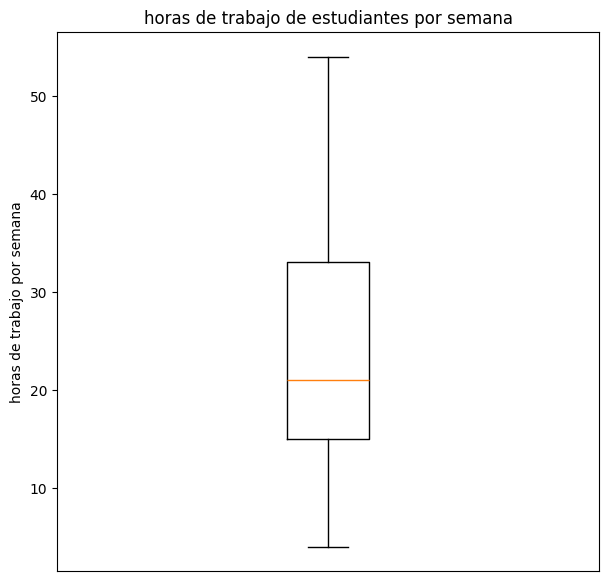

In [ ]:
horas_trabajo = df["horas_trabajo_semana"].dropna()
print(horas_trabajo.describe())

fig, ax = plt.subplots(figsize=(7, 7))
ax.boxplot(horas_trabajo)
ax.set_title("horas de trabajo de estudiantes por semana")
ax.set_xticks([])
ax.set_ylabel("horas de trabajo por semana")
plt.savefig("visualizaciones/caja-horas-trabajo-semana.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿cuántas horas a la semana trabajan los que trabajan? (pregunta 3)

**Observación:** la mediana es 21 horas aproximadamente y la caja va de 15 a 33 horas lo que implica que la mitad de los que trabajan lo hace 21 horas o más, casi medio tiempo. Un apoyo para ellos debe tener horarios flexibles porque les quedan pocas horas para estudiar.

### GRÁFICA 4


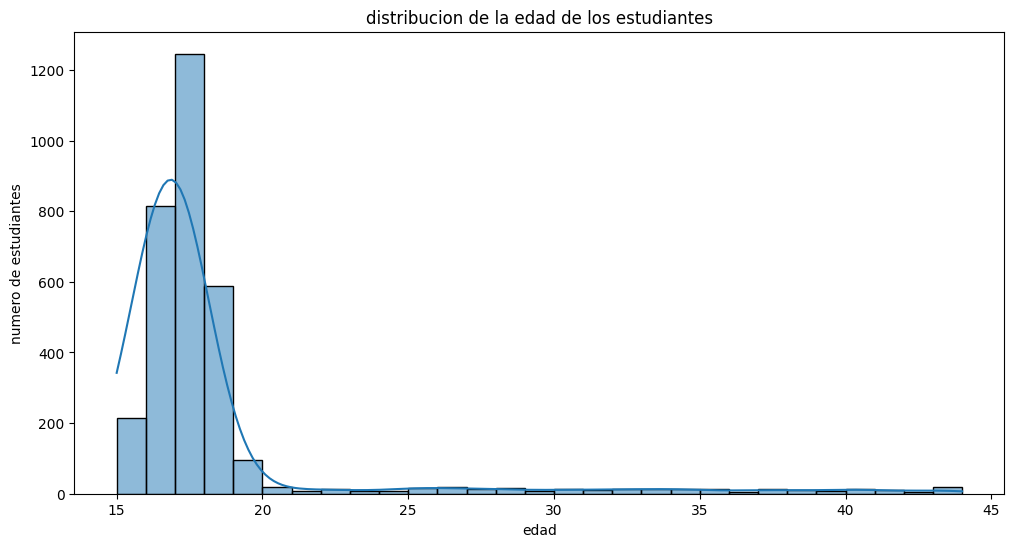

Mayores de 20 anios: 273


In [ ]:
plt.figure(figsize=(12, 6))
ax = sns.histplot(data=df, x="edad", binwidth=1, kde=True)
ax.set_title("distribucion de la edad de los estudiantes")
ax.set_xlabel("edad")
ax.set_ylabel("numero de estudiantes")
plt.savefig("visualizaciones/histograma-kde-edad.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mayores de 20 anios:", (df["edad"] > 20).sum())

**Pregunta:** ¿qué edades tienen los estudiantes? (apoya la pregunta 4)

**Observación:** casi todos tienen entre 15 y 19 años y el pico está en los 17  y de ahi para adelanta va disminuyendo cuando la edad aumenta lo que implica que son extremos en edad y se debe trabajar de forma distinto con los de mayor edad.

Aqui empieza las graficas multivaloradas. Cada una cruza el puntaje global con una o más variables.

### GRÁFICA 5

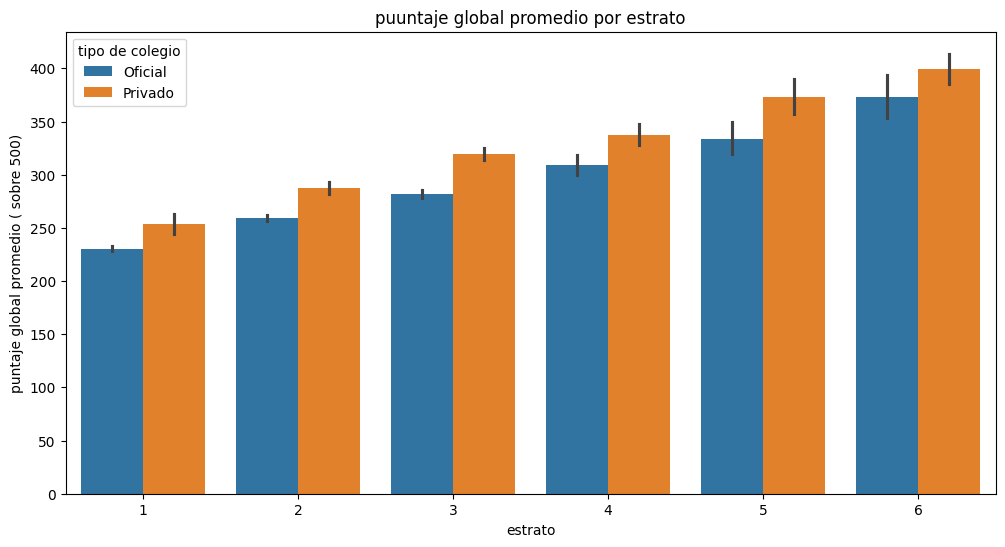

In [ ]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df, x="estrato", y="puntaje_global", hue="tipo_colegio")
ax.set_title("puuntaje global promedio por estrato")
ax.set_xlabel("estrato")
ax.set_ylabel("puntaje global promedio ( sobre 500)")
ax.legend(title="tipo de colegio")
plt.savefig("visualizaciones/barras-puntaje-estrato-y-colegio.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿cómo cambia el puntaje según el estrato y el tipo de colegio? (pregunta 1)

**Observación:** el puntaje sube con cada estrato en el estrato 1 con 230 a 390 en el estrato 6 aproximadamente. en todos los estratos el colegio privado supera al oficial en todos los estractos



### GRÁFICA 6


acceso_internet  computador_hogar
No               No                  235.5
                 Sí                  262.8
Sí               No                  268.3
                 Sí                  298.5
Name: puntaje_global, dtype: float64


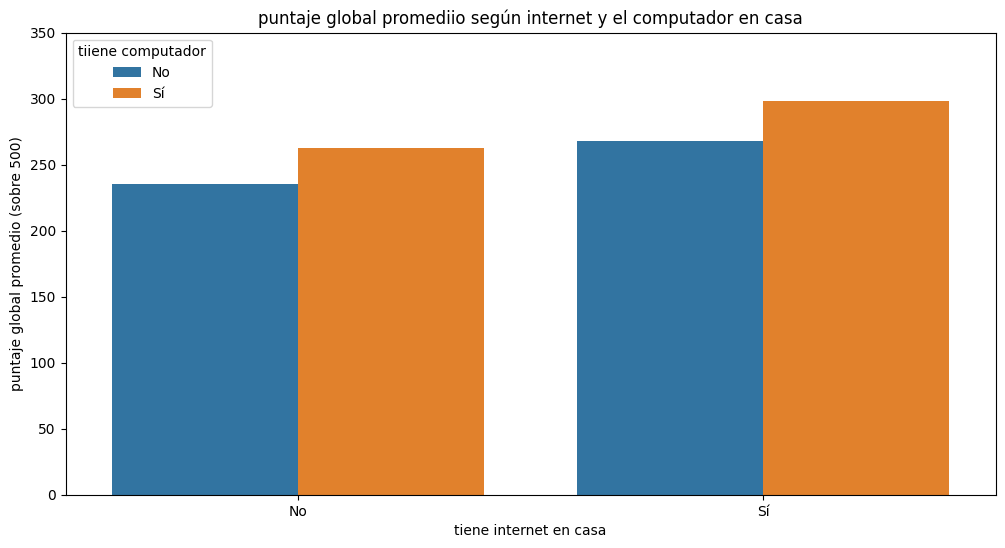

In [ ]:
print(df.groupby(["acceso_internet", "computador_hogar"])["puntaje_global"].mean().round(1))

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df, x="acceso_internet", y="puntaje_global", hue="computador_hogar", hue_order=["No", "Sí"], errorbar=None)
ax.set_title("puntaje global promediio según internet y el computador en casa")
ax.set_xlabel("tiene internet en casa")
ax.set_ylabel("puntaje global promedio (sobre 500)")
ax.set_ylim(0, 350)
ax.legend(title="tiiene computador")
plt.savefig("visualizaciones/barras-puntaje-internet-y-computador.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿tener internet o computador en casa se asocia con mejores resultados? (pregunta 2)

**Observación:** el promedio sube con cada recurso lo que implica los 1.075 estudiantes sin internet ni computador  son el público de un programa de conectividad. Es una asociación y no una causa, porque estos hogares también suelen ser de estratos bajos.

### GRÁFICA 7

pendiente: -0.68
correlacion: -0.15


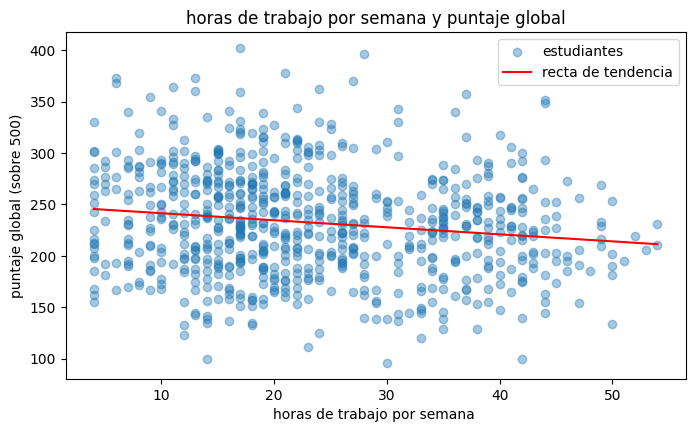

In [ ]:
trabajan = df.loc[df["trabaja"] == "Sí"]
horas = trabajan["horas_trabajo_semana"]
puntaje = trabajan["puntaje_global"]

pendiente, intercepto = np.polyfit(horas, puntaje, 1)
print("pendiente:", round(pendiente, 2))
print("correlacion:", round(horas.corr(puntaje), 2))

horas_ordenadas = horas.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(horas, puntaje, alpha=0.4, label="estudiantes")
ax.plot(horas_ordenadas, pendiente * horas_ordenadas + intercepto, color="red", label="recta de tendencia")
ax.set_title("horas de trabajo por semana y puntaje global")
ax.set_xlabel("horas de trabajo por semana ")
ax.set_ylabel("puntaje global (sobre 500)")
ax.legend()
plt.savefig("visualizaciones/dispersion-horas-trabajo-y-puntaje.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** entre los que trabajan, ¿el puntaje depende de las horas? (pregunta 3)

**Observación:**  755 puntos baja suavemente la recta pierde puntos por cada hora más de trabajo  lo que implica trabajar más horas se asocia con menos puntaje

### GRÁFICA 8.

jornada
Nocturna    228.5
Sabatina    229.0
Única       257.0
Tarde       259.0
Mañana      260.0
Completa    305.0
Name: puntaje_global, dtype: float64


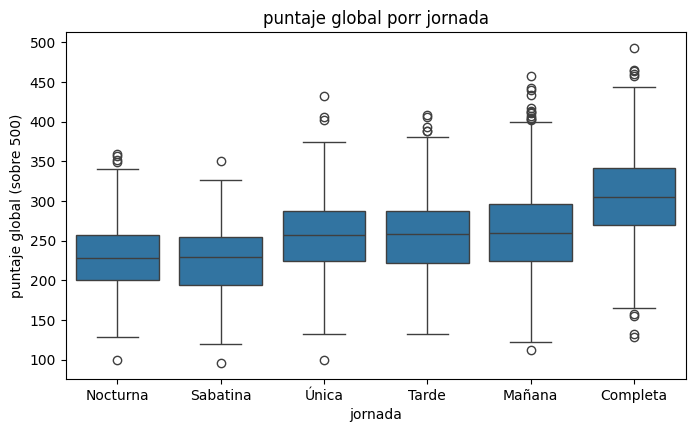

In [ ]:
orden_mediana = df.groupby("jornada")["puntaje_global"].median().sort_values().index
print(df.groupby("jornada")["puntaje_global"].median().sort_values())

plt.figure(figsize=(8, 4.5))
ax = sns.boxplot(data=df, x="jornada", y="puntaje_global", order=orden_mediana)
ax.set_title("puntaje global porr jornada")
ax.set_xlabel("jornada")
ax.set_ylabel("puntaje global (sobre 500)")
plt.savefig("visualizaciones/cajas-puntaje-por-jornada.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿qué jornadas necesitan más apoyo? (pregunta 4)

**Observación:** Sabatina  y Nocturna  tienen las cajas más bajas. Mañana, Tarde y Única están casi iguales y Completa está arriba.lo que implica que nocturna y sabatina son las jornadas prioritarias y allí estudian los mas grandes y que trabajan

### GRÁFICA 9

municipio
Yarumal     237.7
Turbo       241.9
Andes       242.7
Apartadó    242.9
Caucasia    244.9
Rionegro    251.4
Itagüí      269.4
Bello       270.3
Medellín    271.9
Envigado    274.7
Name: puntaje_global, dtype: float64


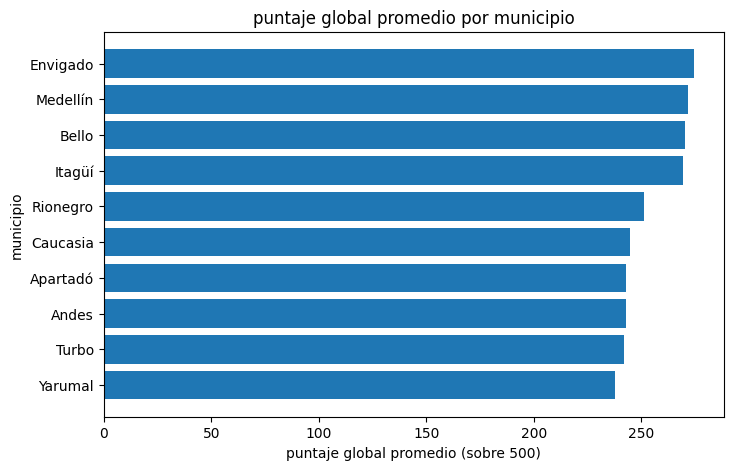

In [ ]:
promedio_municipio = df.groupby("municipio")["puntaje_global"].mean().sort_values()
print(promedio_municipio.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(promedio_municipio.index, promedio_municipio.values)
ax.set_title("puntaje global promedio por municipio")
ax.set_xlabel("puntaje global promedio (sobre 500)")
ax.set_ylabel("municipio")
plt.savefig("visualizaciones/barras-puntaje-por-municipio.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿qué municipios concentran los puntajes más bajos? (pregunta 5)

**Observación:** Yarumal 237, Turbo 241, Andes 242, Apartadó 242 y Caucasia 244 son los más bajos, frente a Envigado 274 y Medellín 271. lo que implica que esos cinco municipios son los que se deben priorizar

### GRÁFICA 10

preparacion_preicfes     No     Sí
estrato                           
1                     229.1  243.8
2                     259.5  273.7
3                     286.9  304.5
4                     303.1  339.7
5                     326.6  359.5
6                     372.3  394.8


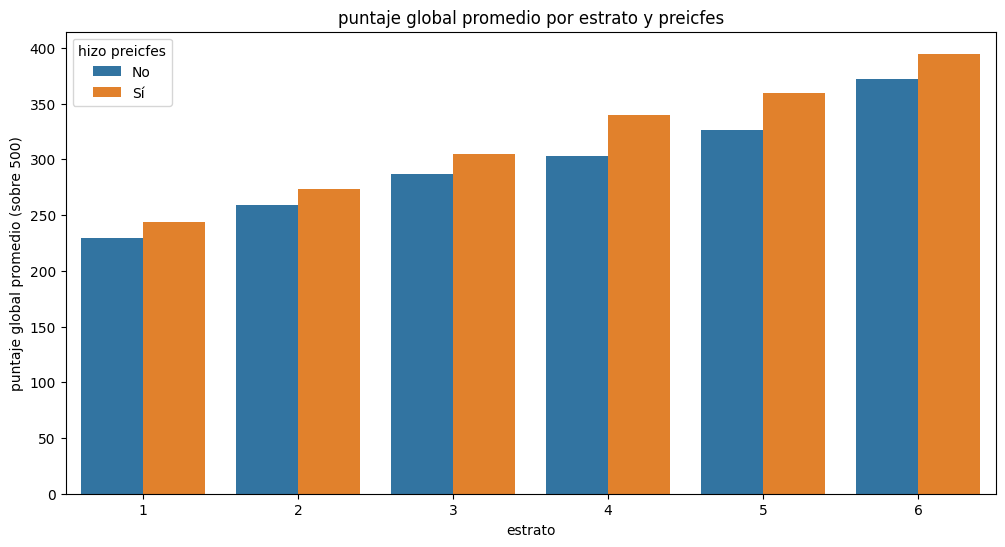

In [ ]:
print(df.groupby(["estrato", "preparacion_preicfes"])["puntaje_global"].mean().round(1).unstack())

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df, x="estrato", y="puntaje_global", hue="preparacion_preicfes", hue_order=["No", "Sí"], errorbar=None)
ax.set_title("puntaje global promedio por estrato y preicfes")
ax.set_xlabel("estrato")
ax.set_ylabel("puntaje global promedio (sobre 500)")
ax.legend(title="hizo preicfes")
plt.savefig("visualizaciones/barras-puntaje-estrato-y-preicfes.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿el preicfes se asocia con mejores puntajes aun dentro del mismo estrato? (pregunta 6)

**Observación:** en todos los estratos los que hicieron preicfes dan mejores resultaods segun el estrato lo que implicaa que  un preicfes gratuito para los estratos 1 y 2  ayudaria.

### GRÁFICA 11

                      estrato  edad  horas_estudio_semana  inasistencias_anio  \
estrato                  1.00 -0.06                  0.03               -0.11   
edad                    -0.06  1.00                 -0.06                0.18   
horas_estudio_semana     0.03 -0.06                  1.00               -0.10   
inasistencias_anio      -0.11  0.18                 -0.10                1.00   
puntaje_global           0.59 -0.17                  0.24               -0.30   

                      puntaje_global  
estrato                         0.59  
edad                           -0.17  
horas_estudio_semana            0.24  
inasistencias_anio             -0.30  
puntaje_global                  1.00  


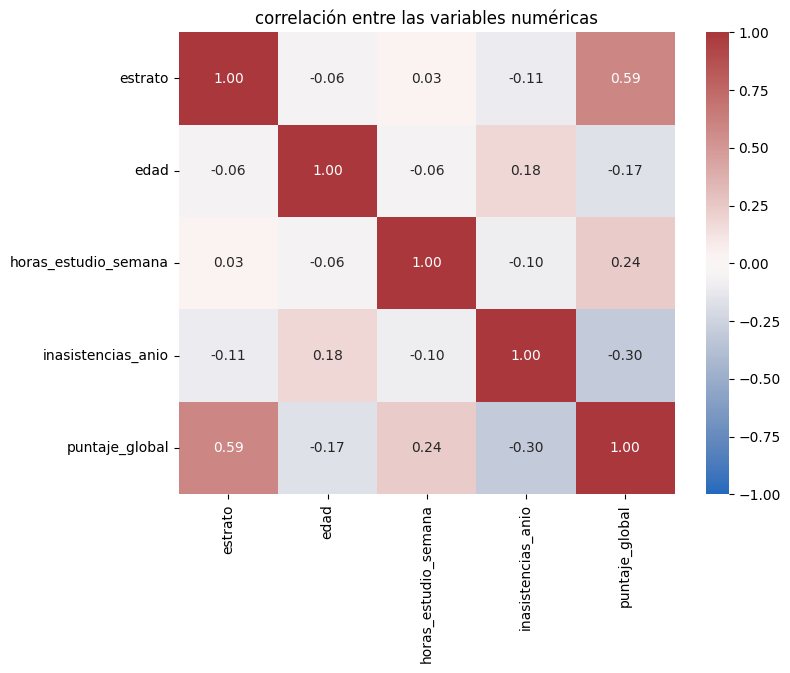

In [ ]:
columnas_numericas = ["estrato", "edad", "horas_estudio_semana", "inasistencias_anio", "puntaje_global"]
corr = df[columnas_numericas].corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
ax.set_title("correlación entre las variables numéricas")
plt.savefig("visualizaciones/mapa-calor-correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()

**Pregunta:** ¿qué variables numéricas se relacionan más con el puntaje global? (apoya las preguntas 1 y 3)

**Observación:** el estrato es la que más se relaciona (0,59). Siguen las inasistencias (−0,30), las horas de estudio (0,24) y la edad (−0,17). El estrato casi no se relaciona con las horas de estudio (0,03).lo que implica que  el estrato pesa más que los hábitos individuales, así que la decisión debe mirar primero las condiciones del hogar. Faltar a clase se asocia con menor puntaje, por eso se podría vigilar la asistencia. La correlación no demuestra causa.